$\textbf{SRM Uncertainty Propagation TEST}$

In [26]:
#DEFINITIONS
import skrf as rf
from skrf.calibration import TRL, TUGMultilineTRL
import numpy as np
import matplotlib.pyplot as plt
from u_srm import uSRM
import metas_unclib as munc
munc.use_linprop()

$\textbf{Add Test Data}$

In [27]:

short = rf.Network('MeasurementData/Short_2Port_raw.s2p')#['0-40GHz']
open = rf.Network('MeasurementData/Open_2Port_raw.s2p')#['0-40GHz']
load = rf.Network('MeasurementData/Match_2Port_raw.s2p')#['0-40GHz']
thru = rf.Network('MeasurementData/Line_0_raw.s2p')#['0-40GHz']
test = rf.Network('MeasurementData/Impedance_raw.s2p')#['0-40GHz']
line_0 = rf.Network('MeasurementData/Line_0_raw.s2p')#['0-40GHz']
line_1 = rf.Network('MeasurementData/Line_1_raw.s2p')#['0-40GHz']
line_2 = rf.Network('MeasurementData/Line_2_raw.s2p')#['0-40GHz']
line_3 = rf.Network('MeasurementData/Line_3_raw.s2p')#['0-40GHz']
line_4 = rf.Network('MeasurementData/Line_4_raw.s2p')#['0-40GHz']
line_5 = rf.Network('MeasurementData/Line_5_raw.s2p')#['0-40GHz']
line_6 = rf.Network('MeasurementData/Line_6_raw.s2p')#['0-40GHz']
FWST = rf.Network('MeasurementData/FWST_Line_0.s1p')#['0-40GHz']
RWST = rf.Network('MeasurementData/RWST_Line_0.s1p')#['0-40GHz']
match_measured = rf.Network('MeasurementData/Match_2Port_raw.s2p')#['0-40GHz']
match_def = rf.Network('match_0402.s1p')#['0-40GHz']
freq = short.frequency


$\textbf{Add Ideals}$

In [28]:
reciprocal_est = np.zeros((len(freq),2,2),dtype=complex)
reciprocal_est[0:len(freq),0,0] = 0*np.ones((len(freq)),dtype=complex)
reciprocal_est[0:len(freq),0,1] = np.ones((len(freq)),dtype=complex)
reciprocal_est[0:len(freq),1,0] = np.ones((len(freq)),dtype=complex)
reciprocal_est[0:len(freq),1,1] = 0*np.ones((len(freq)),dtype=complex)
reciprocal_est = rf.Network(frequency=freq,s=reciprocal_est,z0=50)

short_est = -1*np.ones(len(freq))
open_est = 1*np.ones(len(freq))
match_est = 0*np.ones((len(freq)))

match_est_2p = np.zeros((len(freq),2,2),dtype=complex)
match_est_2p[0:len(freq),0,0] = match_est
match_est_2p[0:len(freq),1,1] = match_est
match_est_2p = rf.Network(frequency=freq,s=match_est_2p,z0=50)

short_est_2p = np.zeros((len(freq),2,2),dtype=complex)
short_est_2p[0:len(freq),0,0] = short_est
short_est_2p[0:len(freq),1,1] = short_est
short_est_2p = rf.Network(frequency=freq,s=short_est_2p,z0=50)

open_est_2p = np.zeros((len(freq),2,2),dtype=complex)
open_est_2p[0:len(freq),0,0] = open_est
open_est_2p[0:len(freq),1,1] = open_est
open_est_2p = rf.Network(frequency=freq,s=open_est_2p,z0=50)

Define some dummy standard deviations for quantities

In [29]:
u_short = 0.005**2
u_open = 0.005**2
u_match = 0.005**2
u_reciprocal = 0.005**2
u_match_def = 0.005**2
u_switch_term = 0.005**2
u_reciprocal_GammaA_short = 0.005**2
u_reciprocal_GammaA_open = 0.005**2
u_reciprocal_GammaA_load = 0.005**2

$\textbf{Perform SRM without Uncertainties}$

In [30]:
calSRM = uSRM(symmetric=[short.s11,short.s22, open.s11, open.s22, load.s11, load.s22],
            est_symmetric=[short_est_2p,  open_est_2p, match_est_2p],
            reciprocal=thru,est_reciprocal=reciprocal_est,
            reciprocal_GammaA = [short.s11, open.s11, load.s11],
            matchA=load.s11, matchB=load.s22,
            matchA_def=match_def.s11, matchB_def=match_def.s11,
            switch_term_fw=FWST.s11, switch_term_bw=RWST.s11,
            usymmetric=[u_short,u_short,u_open,u_open,u_match,u_match],
            ureciprocal=u_reciprocal,
            ureciprocal_GammaA=[u_reciprocal_GammaA_short, u_reciprocal_GammaA_open, u_reciprocal_GammaA_load],
            umatchA_def=u_match_def, umatchB_def=u_match_def,
            umatchA=u_match, umatchB=u_match,
            usw_fw=u_switch_term, usw_bw=u_switch_term)


In [31]:
calSRM.u_run()


uSRM is running...
Frequency: 0.02 GHz ... DONE!
Frequency: 0.04 GHz ... DONE!


C:\Program Files (x86)\METAS\Metas.UncLib\metas_unclib.py:198: ComplexWarning: Casting complex values to real discards the imaginary part
  c = [_Number(float(bi)) for bi in b.flatten('F')]


Frequency: 0.06 GHz ... DONE!
Frequency: 0.08 GHz ... DONE!
Frequency: 0.10 GHz ... DONE!
Frequency: 0.12 GHz ... DONE!
Frequency: 0.14 GHz ... DONE!
Frequency: 0.16 GHz ... DONE!
Frequency: 0.18 GHz ... DONE!
Frequency: 0.20 GHz ... DONE!
Frequency: 0.22 GHz ... DONE!
Frequency: 0.24 GHz ... DONE!
Frequency: 0.26 GHz ... DONE!
Frequency: 0.28 GHz ... DONE!
Frequency: 0.30 GHz ... DONE!
Frequency: 0.32 GHz ... DONE!
Frequency: 0.34 GHz ... DONE!
Frequency: 0.36 GHz ... DONE!
Frequency: 0.38 GHz ... DONE!
Frequency: 0.40 GHz ... DONE!
Frequency: 0.42 GHz ... DONE!
Frequency: 0.44 GHz ... DONE!
Frequency: 0.46 GHz ... DONE!
Frequency: 0.48 GHz ... DONE!
Frequency: 0.50 GHz ... DONE!
Frequency: 0.52 GHz ... DONE!
Frequency: 0.54 GHz ... DONE!
Frequency: 0.56 GHz ... DONE!
Frequency: 0.58 GHz ... DONE!
Frequency: 0.60 GHz ... DONE!
Frequency: 0.62 GHz ... DONE!
Frequency: 0.64 GHz ... DONE!
Frequency: 0.66 GHz ... DONE!
Frequency: 0.68 GHz ... DONE!
Frequency: 0.70 GHz ... DONE!
Frequency:

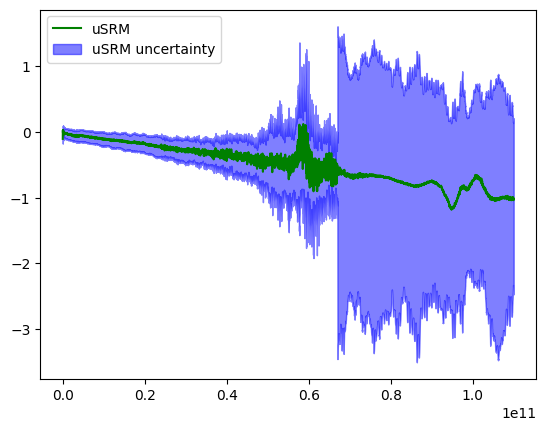

In [32]:
DUT1,unc = calSRM.u_apply_cal(line_6)

plt.figure()
plt.plot(freq.f, 20*np.log10(np.abs(DUT1.to_dataframe('s')['s 21'])),label='uSRM',color='green')
plt.fill_between(freq.f, (20*np.log10(np.abs(DUT1.to_dataframe('s')['s 21'])-(np.abs(unc[:,1,0])))), (20*np.log10(np.abs(DUT1.to_dataframe('s')['s 21'])+(np.abs(unc[:,1,0])))), color='blue', alpha=0.5, label='uSRM uncertainty')
plt.legend()
plt.show()